# 🛡️ Lesson 14 · Deep Learning Optimisation & Regularisation

*“A model that memorises is a student who crams: perfect on the practice test, lost on the exam.”*

| ⏱ Time | 🎚 Level | 🗓 Suggested day | 📚 You should know |
|:--|:--|:--|:--|
| ~140 min | 🔴 Advanced | Day 12–13 | Lessons 05–06, 09 |

## 🎯 Learning objectives
By the end of this lesson you will be able to:

- Explain **overfitting** and recognise it from learning curves: including when it is driven by **noisy labels**
- Apply and explain **L2 weight decay (and AdamW)** versus **L1** sparsity
- Implement **dropout** (inverted) and **batch normalisation** from scratch and explain train-vs-eval behaviour
- Use **early stopping** (with patience and best-weight restore)
- Use **learning-rate schedules** (step, exponential, cosine, one-cycle, warm-up)
- Run a disciplined **ablation study** and read the evidence honestly
- Follow a **practical recipe** for training a new network

## 🗺 Roadmap
1. The generalisation gap
2. Our testbed: small data + noisy labels
3. Weight decay & L1
4. Dropout
5. Batch normalisation
6. Early stopping
7. Learning-rate schedules
8. The ablation study
9. The recipe
10. Problems

## ⚙️ Setup
Run this cell first. It loads our libraries and the course helper module (`utils/dlcourse.py`).

In [1]:
import sys; sys.path.append("..")          # so we can import the course helper library
import numpy as np
import matplotlib.pyplot as plt
from utils import dlcourse as dl
import math, torch, torch.nn as nn
import pandas as pd
from torch.utils.data import TensorDataset, DataLoader
cpu = torch.device('cpu')
dl.set_seed(42)                          # reproducible randomness
%matplotlib inline

---
## 📉 1. The generalisation gap

A model's goal is not to do well on the data it trained on: it's to do well on **new** data. The **generalisation gap** is the difference between the two.

* **Underfitting (high bias):** too simple/too short → bad on both.
* **Overfitting (high variance):** flexible enough to **memorise** training quirks (and noise) → great on train, worse on new data.

```
error │ \                       validation error (U-shaped)
      │  \_                  _/
      │    \_______________/     ← the sweet spot
      │      ╲___________________ training error keeps falling
      └──────────────────────────  model capacity / training time →
```

The techniques in this lesson are all **regularisers**: ways to make memorisation harder or less attractive, so the model learns patterns that *generalise*.

---
## 🧪 2. Our testbed: small data and noisy labels

To see regularisation *matter*, we need a setting where overfitting really bites. We'll use just **2,000 Fashion-MNIST images**, with **25 % of the training labels randomly corrupted**: a realistic stand-in for field data labelled quickly by tired annotators. The **validation labels are clean** (we want the truth about real performance).

A flexible network will happily memorise the wrong labels. Watch it happen:

labels actually changed: 23.2% (some random draws re-pick the true class)


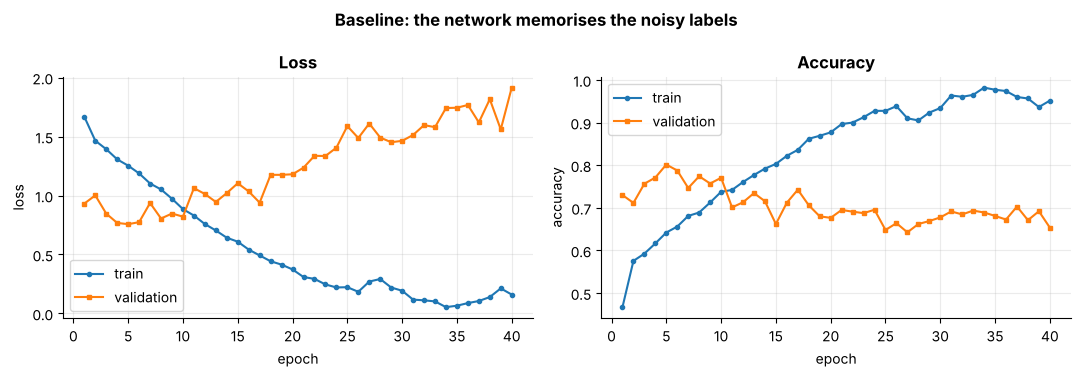

best validation accuracy during training: 80.2%  → at the end: 65.3%


In [2]:
xtr, ytr, xva, yva = dl.load_fashion(n_train=2000, n_test=2000, flatten=True)
rng = np.random.default_rng(0)
corrupt = rng.random(len(ytr)) < 0.25
ytr_noisy = np.where(corrupt, rng.integers(0, 10, len(ytr)), ytr)                     # 25% of labels replaced by random ones
print(f"labels actually changed: {(ytr_noisy != ytr).mean():.1%} (some random draws re-pick the true class)")
mu, sd = xtr.mean(), xtr.std()
T = lambda a: torch.tensor((a - mu) / sd, dtype=torch.float32)
train_dl = DataLoader(TensorDataset(T(xtr), torch.tensor(ytr_noisy)), batch_size=32, shuffle=True)
val_dl = DataLoader(TensorDataset(T(xva), torch.tensor(yva)), batch_size=1000)
ce = nn.CrossEntropyLoss()

def mlp(drop=0.0, bn=False, hidden=512):
    dl.set_seed(0); layers, n_in = [], 784
    for _ in range(2):
        layers += [nn.Linear(n_in, hidden)] + ([nn.BatchNorm1d(hidden)] if bn else []) + [nn.ReLU()] + ([nn.Dropout(drop)] if drop else [])
        n_in = hidden
    return nn.Sequential(*layers, nn.Linear(hidden, 10))

results = {}
def run(name, model, lr=1e-3, wd=0.0, early_stop=False, schedule=None, epochs=40):
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd) if wd else torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs) if schedule == "cosine" else None
    h = dl.fit(model, train_dl, val_dl, ce, opt, epochs=epochs, device=cpu, scheduler=sched,
               early_stopper=dl.EarlyStopper(patience=6) if early_stop else None, verbose=False)
    va_loss, va_acc = dl.evaluate(model, val_dl, ce, cpu)              # evaluate the model we would actually DEPLOY (restored best weights if early-stopped)
    _, tr_acc = dl.evaluate(model, train_dl, ce, cpu)                  # accuracy on the NOISY training labels
    results[name] = {"val acc": va_acc, "val loss": va_loss, "train acc (noisy labels)": tr_acc, "epochs run": len(h["val_acc"]), "peak val acc seen": max(h["val_acc"])}
    return h

h0 = run("1. Baseline (no regularisation)", mlp())
dl.plot_history(h0, "Baseline: the network memorises the noisy labels")
print(f"best validation accuracy during training: {max(h0['val_acc']):.1%}  → at the end: {h0['val_acc'][-1]:.1%}")

**Read this carefully: it is the single most important picture of the lesson.**

* Training accuracy climbs toward ~100 %, but ~22 % of those labels are *wrong*, so reaching much more than ~77 % **proves the network is memorising noise**.
* Validation loss reaches a minimum early, then **climbs** (the model becomes confidently wrong). Validation accuracy peaks and then **declines**.

Everything below tries to keep us near that early sweet spot.

---
## ⚖️ 3. Weight decay (L2) and L1

**Idea:** large weights let the network fit wiggly, over-specific functions. *Penalise* large weights:

$$\mathcal{L}_{total}=\mathcal{L}_{data}+\underbrace{\tfrac{\lambda}{2}\sum w^2}_{L2}\qquad\text{or}\qquad \mathcal{L}_{data}+\underbrace{\lambda\sum |w|}_{L1}$$

* **L2** gradient adds $\lambda w$ → every step **shrinks weights toward zero a little** ("weight decay"). Gentle, smooth.
* **L1** gradient adds $\lambda\,\text{sign}(w)$ → pushes many weights **to (nearly) exactly zero** → *sparse* models, a form of feature selection.
* **AdamW** applies weight decay *separately* from the adaptive gradient step (a subtle bug-fix over L2-in-Adam); in modern practice use `AdamW(weight_decay=0.01–0.1)`.

Let's see the effect on a simple linear classifier (so the weights are easy to look at: one 28×28 weight image per digit):

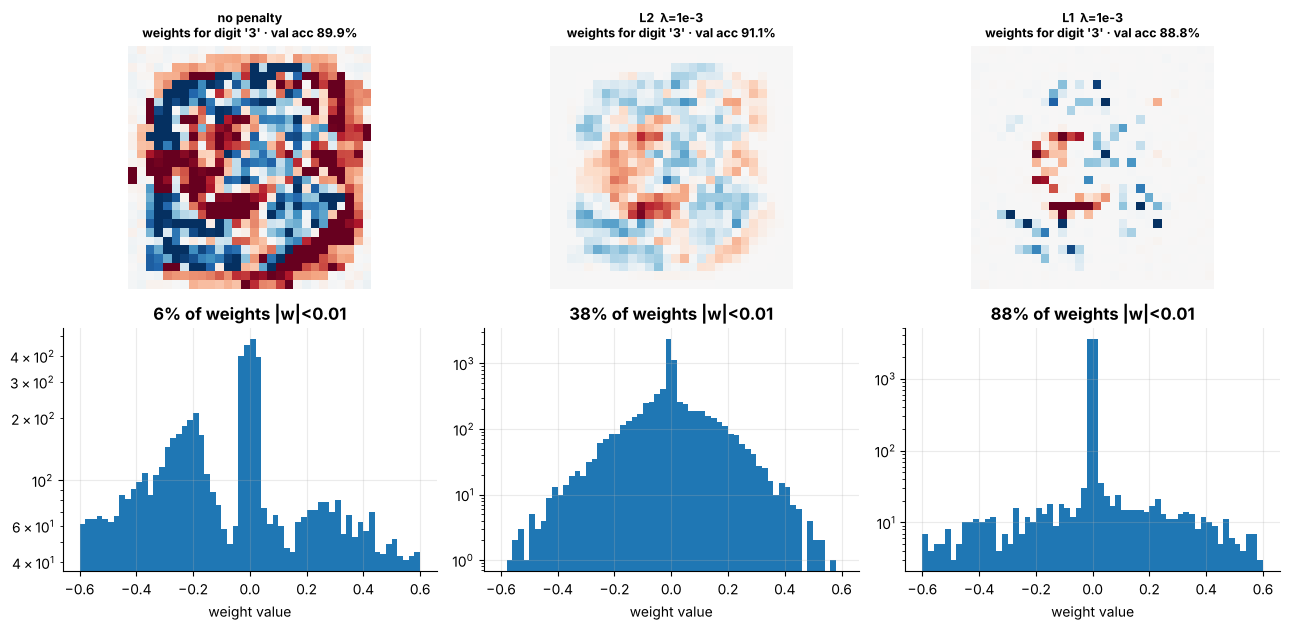

In [3]:
x1, y1, x2, y2 = dl.load_mnist(n_train=2000, n_test=2000, flatten=True)
X, Y, Xv, Yv = map(torch.tensor, (x1, y1, x2, y2))

def train_linear(l1=0.0, l2=0.0, steps=400):
    torch.manual_seed(0); m = nn.Linear(784, 10); opt = torch.optim.Adam(m.parameters(), lr=0.02)
    for _ in range(steps):
        loss = nn.functional.cross_entropy(m(X), Y) + l1 * m.weight.abs().sum() + l2 * (m.weight ** 2).sum()
        opt.zero_grad(); loss.backward(); opt.step()
    return m.weight.detach(), (m(Xv).argmax(1) == Yv).float().mean().item()

configs = [("no penalty", {}), ("L2  λ=1e-3", dict(l2=1e-3)), ("L1  λ=1e-3", dict(l1=1e-3))]
fig, axes = plt.subplots(2, 3, figsize=(13, 6.4))
for k, (name, kw) in enumerate(configs):
    w, acc = train_linear(**kw)
    axes[0, k].imshow(w[3].reshape(28, 28), cmap="RdBu", vmin=-.6, vmax=.6); axes[0, k].set_title(f"{name}\nweights for digit '3' · val acc {acc:.1%}", fontsize=9); axes[0, k].axis("off")
    axes[1, k].hist(w.flatten().numpy(), bins=60, range=(-.6, .6), log=True); axes[1, k].set(xlabel="weight value", title=f"{(w.abs() < 0.01).float().mean():.0%} of weights |w|<0.01")
plt.tight_layout(); plt.show()

The unregularised model uses *every* pixel (noisy speckle). **L2** shrinks and smooths the weights. **L1** zeroes most pixels outright, keeping only the strokes that matter.

In [4]:
h_wd = run("2. + weight decay 0.1 (AdamW)", mlp(), wd=0.1)
print("done -", {k: round(v, 3) for k, v in results["2. + weight decay 0.1 (AdamW)"].items() if k in ("val acc", "val loss")})

done: {'val acc': 0.667, 'val loss': 1.697}


---
## 🎲 4. Dropout

**Idea (Srivastava, Hinton et al., 2014):** during training, randomly **switch off** each neuron with probability $p$. The network can't rely on any single neuron (or a fragile *co-adaptation* of several), so it must learn **redundant, robust** features. It's like training a huge ensemble of thinned networks that share weights.

**Inverted dropout** (what everyone uses): at training time zero a fraction $p$ of activations **and scale the survivors by $1/(1-p)$**, so the *expected* activation stays the same; at test time do **nothing**.

In [5]:
class MyDropout(nn.Module):
    def __init__(self, p=0.5):
        super().__init__(); self.p = p
    def forward(self, x):
        if not self.training or self.p == 0:                 # EVAL MODE: identity
            return x
        keep = (torch.rand_like(x) > self.p).float()          # 1 = keep, 0 = drop
        return x * keep / (1 - self.p)                        # rescale so E[output] = x

d = MyDropout(0.5); x = torch.ones(10000)
d.train(); y = d(x)
print("training : fraction zeroed", f"{(y == 0).float().mean():.2f}", "| survivors scaled to", y.max().item(), "| mean activation", f"{y.mean():.2f} (≈1, preserved!)")
d.eval();  print("eval     : output identical to input:", torch.equal(d(x), x))

training : fraction zeroed 0.49 | survivors scaled to 2.0 | mean activation 1.01 (≈1, preserved!)
eval     : output identical to input: True


> ⚠️ **Watch out**: **`model.train()` vs `model.eval()` is not optional.** Dropout (and BatchNorm) behave differently in the two modes. Forgetting `model.eval()` at inference gives noisy, *random* predictions that change every call. `dl.fit` and `dl.evaluate` handle it for you: in your own loops, you must.

In [6]:
h_do = run("3. + dropout 0.5", mlp(drop=0.5))
print({k: round(v, 3) for k, v in results["3. + dropout 0.5"].items() if k in ("val acc", "val loss", "train acc (noisy labels)")})

{'val acc': 0.777, 'val loss': 0.819, 'train acc (noisy labels)': 0.81}


---
## 📊 5. Batch normalisation

**Idea (Ioffe & Szegedy, 2015):** normalise each feature across the mini-batch to mean 0 / variance 1, then let the network learn a scale $\gamma$ and shift $\beta$:

$$\hat x=\frac{x-\mu_B}{\sqrt{\sigma_B^2+\varepsilon}},\qquad y=\gamma\,\hat x+\beta$$

**Effects:** much faster, more stable training; tolerates larger learning rates; reduces sensitivity to initialisation; and a mild regularising side-effect (each example's normalisation depends on its random batch-mates → noise).

**Train vs eval:** in training it uses the *current batch's* statistics and updates **running averages**; in eval it uses the running averages (so a single image can be predicted). Let's implement the training-mode forward pass and match PyTorch:

In [7]:
def batchnorm_forward(x, gamma, beta, eps=1e-5):
    mu, var = x.mean(0), x.var(0, unbiased=False)          # statistics over the BATCH axis, per feature
    x_hat = (x - mu) / torch.sqrt(var + eps)
    return gamma * x_hat + beta

torch.manual_seed(0)
x = torch.randn(32, 6) * 5 + 3                              # badly scaled features: mean≈3, std≈5
bn = nn.BatchNorm1d(6); bn.train()
ours, theirs = batchnorm_forward(x, bn.weight, bn.bias), bn(x)
print("matches nn.BatchNorm1d (train mode):", torch.allclose(ours, theirs, atol=1e-5))
print("output mean ≈", ours.mean(0).detach().round(decimals=3).tolist(), "| std ≈", ours.std(0, unbiased=False).detach().round(decimals=3).tolist())
bn.eval(); print("running mean after one batch (momentum 0.1):", bn.running_mean.round(decimals=2).tolist(), "← eval mode uses these")

matches nn.BatchNorm1d (train mode): True
output mean ≈ [-0.0, 0.0, -0.0, -0.0, -0.0, 0.0] | std ≈ [1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
running mean after one batch (momentum 0.1): [0.33000001311302185, 0.23000000417232513, 0.47999998927116394, 0.28999999165534973, 0.11999999731779099, 0.38999998569488525] ← eval mode uses these


> ⚠️ **BatchNorm pitfalls:** (1) very small batches give noisy statistics (use `GroupNorm`/`LayerNorm` instead; Transformers use LayerNorm); (2) forgetting `eval()`; (3) the train/eval discrepancy can bite when the deployment data distribution differs from training.

Does it help *our* problem?

In [8]:
h_bn = run("4. + batch-norm", mlp(bn=True), lr=3e-4)
print({k: round(v, 3) for k, v in results["4. + batch-norm"].items() if k in ("val acc", "val loss", "train acc (noisy labels)")})

{'val acc': 0.667, 'val loss': 1.355, 'train acc (noisy labels)': 0.997}


---
## ⏹ 6. Early stopping

The simplest, cheapest regulariser: **stop training when the validation loss stops improving**, and **restore the weights from the best epoch**.

* **patience**: how many epochs without improvement to tolerate (noise!). Too small: stop prematurely; too big: overshoot.
* Always **restore the best weights**: otherwise you keep the *worse*, later model.
* The validation set is now *part of training* (it chooses the stopping epoch), so keep a **separate test set** for the final score (Lesson 07).

The logic is tiny (`dl.EarlyStopper` in `utils/dlcourse.py`: read it!). You'll implement it as Problem 4.

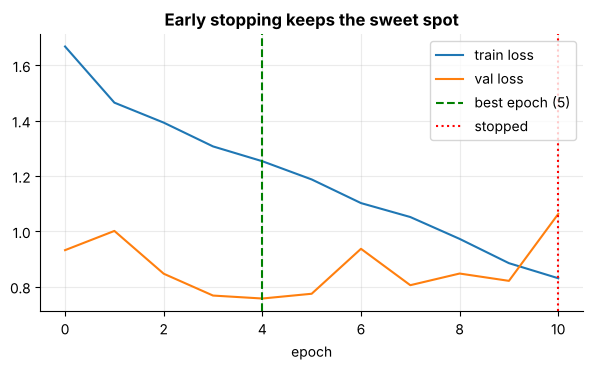

{'val acc': 0.801, 'val loss': 0.757, 'epochs run': 11}


In [9]:
h_es = run("5. + early stopping (patience 6)", mlp(), early_stop=True)
best_epoch = int(np.argmin(h_es["val_loss"])) + 1
plt.figure(figsize=(7, 3.6)); plt.plot(h_es["train_loss"], label="train loss"); plt.plot(h_es["val_loss"], label="val loss")
plt.axvline(best_epoch - 1, c="g", ls="--", label=f"best epoch ({best_epoch})"); plt.axvline(len(h_es["val_loss"]) - 1, c="r", ls=":", label="stopped"); plt.legend(); plt.xlabel("epoch"); plt.title("Early stopping keeps the sweet spot"); plt.show()
print({k: round(v, 3) for k, v in results["5. + early stopping (patience 6)"].items() if k in ("val acc", "val loss", "epochs run")})

---
## 🎢 7. Learning-rate schedules

A good learning rate *changes* during training: big at first (explore), small at the end (settle into a minimum). Common schedules:

| Schedule | Shape | Notes |
|:--|:--|:--|
| **StepLR** | Drop by ×γ every *k* epochs | Classic; needs hand-tuned steps |
| **ExponentialLR** | Smooth ×γ per epoch | Simple |
| **CosineAnnealingLR** | Half-cosine from max → ~0 | Very popular default; no extra hyperparameters |
| **OneCycleLR** | Warm up to a peak, then anneal | Fast convergence ("super-convergence") |
| **Warm-up + cosine** | Short linear ramp, then cosine | Standard for Transformers (stabilises early training) |
| **ReduceLROnPlateau** | ×γ when validation stops improving | Reactive; no schedule to design |

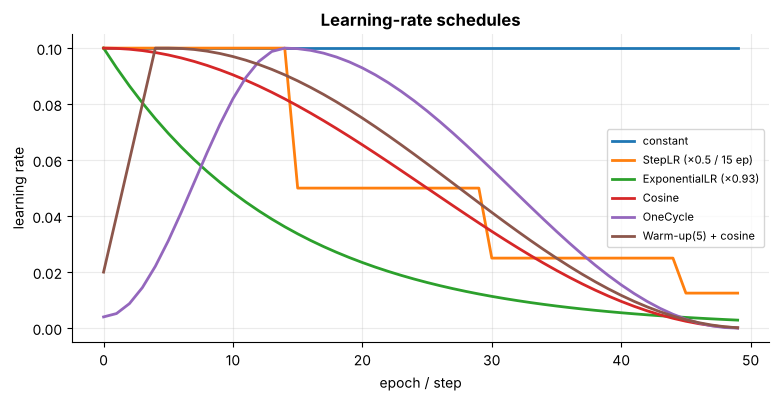

In [10]:
def lr_curve(make_sched, steps=50):
    p = nn.Parameter(torch.zeros(1)); opt = torch.optim.SGD([p], lr=0.1); sched = make_sched(opt); lrs = []
    for _ in range(steps):
        lrs.append(opt.param_groups[0]["lr"]); opt.step(); sched.step()
    return lrs

S = torch.optim.lr_scheduler
curves = {
    "constant": lr_curve(lambda o: S.LambdaLR(o, lambda e: 1.0)),
    "StepLR (×0.5 / 15 ep)": lr_curve(lambda o: S.StepLR(o, 15, 0.5)),
    "ExponentialLR (×0.93)": lr_curve(lambda o: S.ExponentialLR(o, 0.93)),
    "Cosine": lr_curve(lambda o: S.CosineAnnealingLR(o, 50)),
    "OneCycle": lr_curve(lambda o: S.OneCycleLR(o, max_lr=0.1, total_steps=50)),
    "Warm-up(5) + cosine": lr_curve(lambda o: S.LambdaLR(o, lambda e: (e + 1) / 5 if e < 5 else 0.5 * (1 + math.cos(math.pi * (e - 5) / 45)))),
}
plt.figure(figsize=(9, 4))
for name, c in curves.items(): plt.plot(c, label=name, lw=2)
plt.xlabel("epoch / step"); plt.ylabel("learning rate"); plt.legend(fontsize=8); plt.title("Learning-rate schedules"); plt.show()

In [11]:
h_cos = run("6. + cosine LR schedule", mlp(), schedule="cosine")
print({k: round(v, 3) for k, v in results["6. + cosine LR schedule"].items() if k in ("val acc", "val loss")})

{'val acc': 0.709, 'val loss': 1.443}


---
## 🔬 8. The ablation study

Now combine: **dropout + weight decay + cosine schedule + early stopping**, and compare every row. A fair comparison uses the *same* data, seed and epoch budget.

,val acc,val loss,train acc (noisy labels),peak val acc seen,epochs run
1. Baseline (no regularisation),0.654,1.915,0.953,0.802,40.0
2. + weight decay 0.1 (AdamW),0.667,1.697,0.991,0.800,40.0
3. + dropout 0.5,0.777,0.819,0.810,0.802,40.0
4. + batch-norm,0.668,1.355,0.997,0.799,40.0
5. + early stopping (patience 6),0.802,0.757,0.684,0.802,11.0
6. + cosine LR schedule,0.708,1.443,1.000,0.797,40.0
7. Dropout 0.5 + wd 0.05 + cosine,0.794,0.751,0.832,0.812,40.0
8. Everything (drop.3+BN+wd+cos+ES),0.794,0.708,0.676,0.794,10.0


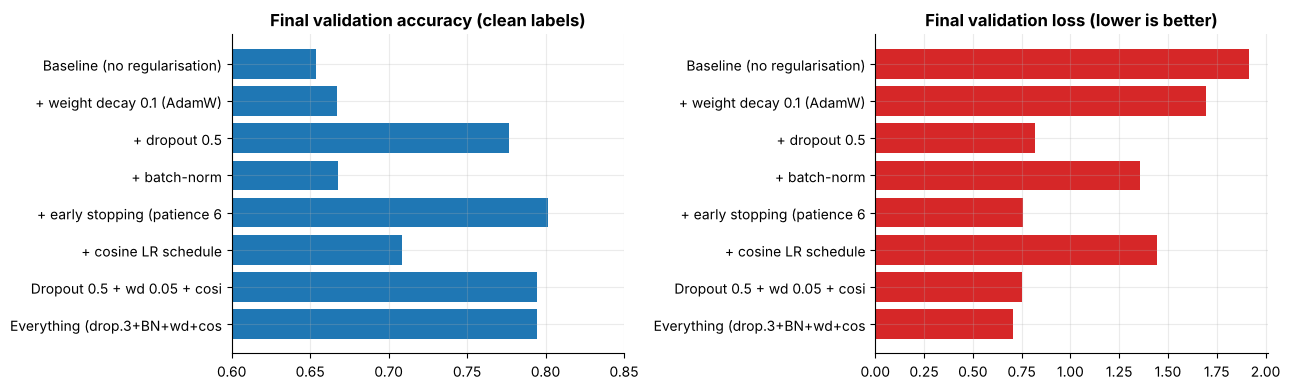

In [12]:
run("7. Dropout 0.5 + wd 0.05 + cosine", mlp(drop=0.5), wd=0.05, schedule="cosine")
run("8. Everything (drop.3+BN+wd+cos+ES)", mlp(drop=0.3, bn=True), lr=1e-3, wd=0.05, schedule="cosine", early_stop=True)

table = pd.DataFrame(results).T
display(table[["val acc", "val loss", "train acc (noisy labels)", "peak val acc seen", "epochs run"]].round(3))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
names = [n.split(". ")[1][:28] for n in table.index]
ax[0].barh(names, table["val acc"], color="tab:blue"); ax[0].set(xlim=(0.6, 0.85), title="Final validation accuracy (clean labels)")
ax[1].barh(names, table["val loss"], color="tab:red"); ax[1].set(title="Final validation loss (lower is better)")
for a in ax: a.invert_yaxis()
plt.tight_layout(); plt.show()

**What the evidence says** *(numbers vary slightly by seed; read the pattern)*

* The **baseline** ends well below its own peak: it memorised the noise.
* **Dropout** and **early stopping** are the standouts here: they cap memorisation and keep both validation accuracy and loss near the sweet spot. **Weight decay** and **cosine alone** help only modestly; **BatchNorm** mostly speeds optimisation and helps loss.
* **Combinations** are not guaranteed to add up: regularisers overlap, and over-regularising (too much dropout *and* weight decay) *underfits*.
* With **clean** labels and more data, differences are much smaller (we saw that on MNIST). **Regularisation matters most when data is small or noisy**: exactly the situation in many agricultural projects.

> 🧠 **Scientific habit:** an ablation changes **one thing at a time** and reports what *didn't* help too. Differences of ~1 % on 2,000 validation images are within noise (std. error ≈ 1 %); repeat with several seeds before claiming a winner.

---
## 🧰 9. The recipe: how to train a new network (adapted from Karpathy)

1. **Become one with the data.** Look at images, label noise, class balance, outliers.
2. **Set up the pipeline & a dumb baseline** (majority class, linear/ridge). Fix seeds. Check the **initial loss ≈ ln k**.
3. **Overfit one tiny batch** to ~0 loss. If you can't, you have a bug.
4. **Overfit the full training set** with a model that's big enough (training loss → ~0). *Now* you know the pipeline works and capacity isn't the limit.
5. **Regularise**, in this order of bang-for-buck: **more data / augmentation** → **early stopping** → **dropout / weight decay** → smaller model.
6. **Tune** learning rate first (log scale), then batch size, then architecture; use **random search**, not grids; log everything.
7. **Squeeze:** schedules, ensembles, test-time augmentation: last, for the final 1–2 %.
8. **Report honestly:** validation for choices, test **once**, with seeds/variance and limitations.

---
# 🏋️ Practice problems
Work through these in order. Each problem has **hints** (open them one at a time: struggling a little is how learning happens!) and a **self-check cell** that tells you ✅ or ❌. Full solutions live in `../solutions/`.

*Difficulty:* ⭐ warm-up · ⭐⭐ standard · ⭐⭐⭐ challenge

---
### 🧩 Problem 14.1: Inverted dropout  &nbsp; `⭐⭐`

Implement `dropout(x, p, training, rng)` (NumPy). In training mode: zero each element with probability `p` and scale the kept ones by `1/(1−p)`. In eval mode: return `x` unchanged. Use the provided `rng` (`np.random.default_rng`) for the random mask.

<details><summary>💡 Hint 1</summary>

`keep = rng.random(x.shape) >= p` gives a boolean mask (True = keep).

</details>

<details><summary>💡 Hint 2</summary>

Training output: `x * keep / (1 - p)`.

</details>

<details><summary>💡 Hint 3</summary>

Check `training` first and return `x` early when it's False.

</details>


In [ ]:
def dropout(x, p, training, rng):
    pass

In [ ]:
# ▶ self-check (run after you've written your answer)
rng = np.random.default_rng(0); x = np.ones(200000)
y = dropout(x, 0.3, True, rng)
dl.check("about 30% zeroed", y is not None and abs((y == 0).mean() - 0.3) < 0.01)
dl.check("survivors are scaled to 1/(1-p)", y is not None and np.allclose(y[y != 0], 1 / 0.7))
dl.check("expected value preserved (mean ≈ 1)", y is not None and abs(y.mean() - 1) < 0.01)
dl.check("eval mode is the identity", np.array_equal(dropout(x, 0.3, False, rng), x))

---
### 🧩 Problem 14.2: Batch-norm forward pass  &nbsp; `⭐⭐`

Implement `batchnorm_forward(x, gamma, beta, eps=1e-5)` for `x` of shape `(batch, features)` using **batch** statistics (biased variance, `unbiased=False`/`ddof=0`). The check compares with `nn.BatchNorm1d` in training mode.

<details><summary>💡 Hint 1</summary>

Statistics over axis 0: `mu = x.mean(0)`, `var = x.var(0, unbiased=False)` (torch) .

</details>

<details><summary>💡 Hint 2</summary>

`x_hat = (x - mu) / torch.sqrt(var + eps)`.

</details>

<details><summary>💡 Hint 3</summary>

Return `gamma * x_hat + beta`.

</details>


In [ ]:
def batchnorm_forward(x, gamma, beta, eps=1e-5):
    pass

In [ ]:
# ▶ self-check (run after you've written your answer)
torch.manual_seed(1); x = torch.randn(16, 5) * 3 + 2
bn = nn.BatchNorm1d(5); nn.init.uniform_(bn.weight, 0.5, 1.5); nn.init.uniform_(bn.bias, -1, 1); bn.train()
out = batchnorm_forward(x, bn.weight, bn.bias)
dl.check("matches nn.BatchNorm1d (train mode)", out is not None and torch.allclose(out, bn(x), atol=1e-5))
z = batchnorm_forward(x, torch.ones(5), torch.zeros(5))
dl.check("with γ=1, β=0 each feature has mean 0 and std 1", z is not None and torch.allclose(z.mean(0), torch.zeros(5), atol=1e-5) and torch.allclose(z.std(0, unbiased=False), torch.ones(5), atol=1e-3))

---
### 🧩 Problem 14.3: Cosine schedule by formula  &nbsp; `⭐⭐`

Implement `cosine_lr(t, T, lr_max, lr_min=0.0)` = `lr_min + ½(lr_max − lr_min)(1 + cos(π·t/T))` for step `t` out of `T`. Compare with PyTorch's `CosineAnnealingLR`.

<details><summary>💡 Hint 1</summary>

`math.cos(math.pi * t / T)`.

</details>

<details><summary>💡 Hint 2</summary>

At `t = 0` you get `lr_max`; at `t = T` you get `lr_min`; halfway you get the midpoint.

</details>


In [ ]:
def cosine_lr(t, T, lr_max, lr_min=0.0):
    pass

In [ ]:
# ▶ self-check (run after you've written your answer)
dl.check("starts at lr_max", cosine_lr(0, 50, 0.1) is not None and np.isclose(cosine_lr(0, 50, 0.1), 0.1))
dl.check("midpoint is lr_max/2", cosine_lr(25, 50, 0.1) is not None and np.isclose(cosine_lr(25, 50, 0.1), 0.05))
p = nn.Parameter(torch.zeros(1)); opt = torch.optim.SGD([p], lr=0.1); sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, 50, eta_min=0.001)
ok = True
for t in range(50):
    v = cosine_lr(t, 50, 0.1, 0.001)
    ok &= v is not None and np.isclose(v, opt.param_groups[0]["lr"], atol=1e-9)
    opt.step(); sch.step()
dl.check("matches torch's CosineAnnealingLR at every step", ok)

---
### 🧩 Problem 14.4: Early-stopping logic  &nbsp; `⭐⭐`

Write `early_stopping(val_losses, patience)`. Walk through the validation losses epoch by epoch (epochs numbered from 1). Track the best loss so far and the number of epochs since it last improved (strictly lower).
Stop as soon as that counter reaches `patience`. Return `(stop_epoch, best_epoch)`; if training never triggers a stop, `stop_epoch` is the last epoch.

<details><summary>💡 Hint 1</summary>

Keep `best = inf`, `best_epoch = 0`, `wait = 0`.

</details>

<details><summary>💡 Hint 2</summary>

If `loss < best`: update `best`, `best_epoch`, reset `wait = 0`; else `wait += 1`.

</details>

<details><summary>💡 Hint 3</summary>

After updating, `if wait >= patience: return epoch, best_epoch`.

</details>


In [ ]:
def early_stopping(val_losses, patience):
    pass

In [ ]:
# ▶ self-check (run after you've written your answer)
losses = [1.0, 0.8, 0.6, 0.55, 0.58, 0.57, 0.56, 0.54, 0.6]
dl.check("patience 3 → stops at epoch 7, best was epoch 4", early_stopping(losses, 3) == (7, 4))
dl.check("patience 5 → epoch 8 improves (0.54), so no stop until the end: (9, 8)", early_stopping(losses, 5) == (9, 8))
dl.check("always improving → never stops early", early_stopping([5, 4, 3, 2, 1], 2) == (5, 5))

---
### 🧩 Problem 14.5: L2 penalty = weight decay  &nbsp; `⭐`

Write `sgd_step_l2(w, grad, lr, lam)` returning the new weights after a plain SGD step on `loss + (lam/2)·Σw²`: i.e. `w − lr·(grad + lam·w)`. Then confirm it equals PyTorch's `SGD(weight_decay=lam)` (which does exactly this).

<details><summary>💡 Hint 1</summary>

The gradient of `(lam/2)·w²` is `lam·w`.

</details>

<details><summary>💡 Hint 2</summary>

New weights: `w - lr * (grad + lam * w)`.

</details>


In [ ]:
def sgd_step_l2(w, grad, lr, lam):
    pass

In [ ]:
# ▶ self-check (run after you've written your answer)
w0 = torch.tensor([1.0, -2.0, 3.0]); g = torch.tensor([0.5, 0.5, -1.0])
mine = sgd_step_l2(w0.clone(), g, 0.1, 0.01)
p = nn.Parameter(w0.clone()); opt = torch.optim.SGD([p], lr=0.1, weight_decay=0.01); p.grad = g.clone(); opt.step()
dl.check("matches torch SGD(weight_decay)", mine is not None and torch.allclose(mine, p.detach()))
dl.check("weights shrink even with zero data gradient", torch.all(sgd_step_l2(w0.clone(), torch.zeros(3), 0.1, 0.1).abs() < w0.abs()))

---
## 🏁 Key takeaways
- ✅ **Overfitting** = memorising training quirks/noise: train metrics keep improving while validation loss turns up. It's worst with **small or noisy data**.
- ✅ **Weight decay (L2)** shrinks weights (use **AdamW**); **L1** makes them sparse.
- ✅ **Dropout** randomly silences neurons in training (scaled by 1/(1−p)); identity at eval. **BatchNorm** normalises per batch, uses running stats at eval: both need `model.train()/eval()` discipline.
- ✅ **Early stopping** (patience + restore best weights) is the cheapest, most reliable regulariser.
- ✅ **LR schedules** (cosine, one-cycle, warm-up) help optimisation: big steps first, small steps to settle.
- ✅ Do **ablations** one change at a time, repeat across seeds, report what *didn't* help, and follow the recipe: **overfit first, then regularise**.

---
## 🧠 Check your understanding
Try to answer *out loud* before you open the answer. If you can explain it to a friend, you own it.
**Q1.** Training accuracy 100 %, validation accuracy 78 %, validation loss rising. Diagnosis and three fixes?

<details><summary>Answer</summary>

Overfitting. Add data/augmentation, apply dropout and/or weight decay, early-stop, or reduce model size.

</details>

**Q2.** Why do we scale surviving activations by 1/(1−p) during dropout training?

<details><summary>Answer</summary>

To keep the expected sum of activations the same as at test time (when no neurons are dropped), so no re-scaling is needed at inference.

</details>

**Q3.** Why does BatchNorm behave differently in `train()` and `eval()` mode?

<details><summary>Answer</summary>

In training it normalises using the current batch's statistics (and updates running averages); at inference it uses the stored running averages so predictions don't depend on batch-mates.

</details>

**Q4.** After early stopping at epoch 20 with best epoch 14, which weights should you keep?

<details><summary>Answer</summary>

The epoch-14 weights (restore the best checkpoint): the later ones are already overfitting.

</details>

**Q5.** Why is the *validation* set no longer 'unseen' once you use it for early stopping, and what do you do about it?

<details><summary>Answer</summary>

It influenced which epoch/model we picked. Keep a separate **test** set for the final unbiased estimate.

</details>

---
## 📚 Go deeper (optional)
- Karpathy: *A Recipe for Training Neural Networks* (blog)
- Srivastava et al. (2014): *Dropout: a simple way to prevent neural networks from overfitting*
- Ioffe & Szegedy (2015) (*Batch Normalization*; Ba et al. (2016)) *Layer Normalization*
- Loshchilov & Hutter (2019): *Decoupled Weight Decay Regularization* (AdamW); *SGDR* (cosine with restarts)
- Zhang et al. (2017): *Understanding deep learning requires rethinking generalization* (networks memorise random labels)

---
⬅️ Previous: [13 · Transformers & Attention](13_transformers.ipynb) &nbsp;|&nbsp; Next: [15 · Keras & TensorFlow Bridge](15_keras_tensorflow_bridge.ipynb) ➡️